# AgriStress-500 End-to-End Pipeline

Download the dataset -> sample a cluster plus cross-cluster distractors -> generate embeddings via the PAI embedding API -> run Image-to-Image evaluation, using the `precisionai.agriemb` package that wires the three sibling projects together:

- [Precision AI Embeddings](https://embeddings.precision.ai/) - hosted image embedding API
- [`agrieval`](https://github.com/Precision-AI-Inc/agrieval) - embedding evaluation
- [`agristress-utils`](https://github.com/Precision-AI-Inc/agristress-utils) - dataset download and sampling

**Setup** (from the repo root, before starting Jupyter):

```bash
pip install -e ".[notebook]"
cp .env.example .env   # fill in PAI_EMBEDDINGS_BASE_URL and PAI_EMBEDDINGS_API_KEY
```

Run all cells top-to-bottom. See the root `README.md` and the standalone `examples/01_download_dataset.py` plus `examples/image2image/01_sample_cluster.py`-`03_run_eval.py` (or the bundled `04_end_to_end.py`) scripts for the non-notebook version.

In [1]:
import io
from pathlib import Path, PurePosixPath

import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image as IPythonImage
from IPython.display import display
from PIL import Image

from precisionai.agriemb import (
    build_client,
    download,
    embed_images,
    print_evaluation,
    run_i2i_evaluation,
    sample_cluster_with_distractors,
    verify_dataset,
)
from precisionai.agriemb.config import DEFAULT_DATASET_DIR, DEFAULT_MODEL, DEFAULT_REPO_ID
from precisionai.agrieval.emb import plot_cosine_similarity, plot_knn_confusion, plot_tsne
from precisionai.agristress.utils import AgriStressDataset, normalize_embeddings, validate_embeddings

SEED = 0
CLUSTER = "A1"
NUM_SAMPLES = 8
NUM_DISTRACTOR_CLUSTERS = 6
NUM_DISTRACTOR_SAMPLES = 2

# Emit a static PNG alongside each interactive Plotly figure, so the committed
# outputs still render where plotly.js is unavailable (GitHub, plain HTML
# exports). Needs `kaleido` and a Chrome install; without them we keep the
# interactive figure only rather than failing the cell.
try:
    go.Figure().to_image(format="png")
    pio.renderers.default = "plotly_mimetype+png"
except Exception as err:  # any kaleido/Chrome problem here is non-fatal
    pio.renderers.default = "plotly_mimetype"
    print(f"Static PNG fallback unavailable ({type(err).__name__}); figures will be interactive only.")

## 1. Download the dataset

The dataset is ~12 GB across 4950 files and takes 20+ minutes on a fast connection. `verify_dataset` reports which manifest-referenced files are missing, so a complete copy is reused instead of re-walking all 4950 files. The download resumes if it is interrupted, so just re-run this cell.

In [2]:
missing = verify_dataset(DEFAULT_DATASET_DIR)
if missing:
    print(f"{len(missing)} file(s) missing; downloading (~12 GB in full, 20+ minutes)...")
    dataset_dir = download(DEFAULT_DATASET_DIR, repo_id=DEFAULT_REPO_ID)
else:
    dataset_dir = Path(DEFAULT_DATASET_DIR)
    print("Dataset already complete; skipping the download.")

dataset = AgriStressDataset(dataset_dir)
clusters = dataset.list_clusters()

parts = dataset_dir.parts
display_dir = Path(*parts[parts.index("examples") :]) if "examples" in parts else dataset_dir
print(f"Dataset  : {display_dir}")
print(f"Clusters : {len(clusters)}")
print(f"Images   : {len(dataset.list_image_ids())}")

Dataset already complete; skipping the download.
Dataset  : examples/data/agristress
Clusters : 121
Images   : 451


## 2. Sample a query cluster plus distractors

Image→Image counts same-cluster images as relevant, so a sample drawn from one cluster has no negatives at all and every precision and nDCG figure comes out at 1.0000 whatever the embeddings do. `sample_cluster_with_distractors` adds `NUM_DISTRACTOR_SAMPLES` images from each of `NUM_DISTRACTOR_CLUSTERS` other clusters, giving the ranking something it can get wrong.

`CLUSTER` defaults to `"A1"`, one of the few well-populated clusters; 104 of AgriStress-500's 121 clusters hold fewer than 8 images. Set it to `None` for a random cluster, or to any id from `clusters` above.

In [3]:
cluster, sample, distractors = sample_cluster_with_distractors(
    dataset,
    cluster=CLUSTER,
    num_samples=NUM_SAMPLES,
    num_distractor_clusters=NUM_DISTRACTOR_CLUSTERS,
    num_distractor_samples=NUM_DISTRACTOR_SAMPLES,
    seed=SEED,
)
selection = sample + distractors
paths = dataset.resolve_paths(selection)

distractor_clusters = sorted({PurePosixPath(image_id).parent.name or image_id for image_id in distractors})
print(f"Query cluster {cluster}: sampled {len(sample)} of {len(dataset.list_image_ids(cluster=cluster))} images")
print(f"Distractors           : {len(distractors)} from {distractor_clusters}")

Query cluster A1: sampled 8 of 16 images
Distractors           : 12 from ['B1', 'G1', 'K5', 'L1', 'M4', 'N3']


### Preview the sampled images

The query cluster's images come first, then the distractors.

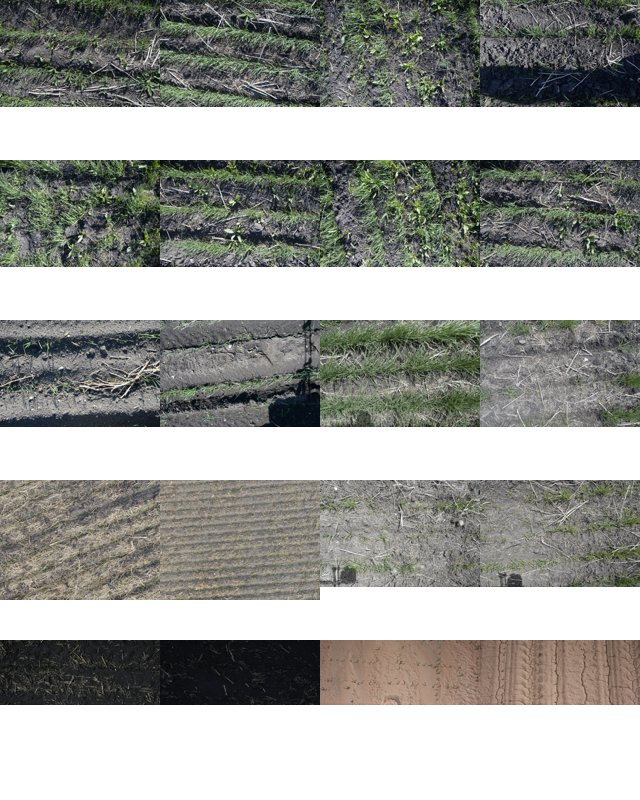

images/A1/pai-SbcQ1Av0.png
images/A1/pai-fMEceubf.png
images/A1/pai-Ooz3Qfkt.png
images/A1/pai-OtvXFt3d.png
images/A1/pai-WIjTCT7r.png
images/A1/pai-M2lh8fY1.png
images/A1/pai-UEr840F9.png
images/A1/pai-LsPNHYpV.png
images/K5/pai-fuOSVtsV.png
images/K5/pai-Y0nOpRXA.png
images/L1/pai-QykgTYtO.png
images/L1/pai-DRBuvf8n.png
images/B1/pai-V9Y63ieo.png
images/B1/pai-5t8abaX0.png
images/G1/pai-cY8ABgKO.png
images/G1/pai-WoTydW6t.png
images/N3/pai-m9nBstFG.png
images/N3/pai-2NqJx67a.png
images/M4/pai-tO1Rqxly.png
images/M4/pai-SEi1LCSd.png


In [4]:
thumb_size = 160
cols = 4
items = selection
rows = (len(items) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, item_id in enumerate(items):
    thumb = Image.open(paths[item_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

# JPEG only: `display(sheet)` would embed the same pixels twice (JPEG and PNG),
# which is most of this notebook's committed size.
buffer = io.BytesIO()
sheet.save(buffer, format="JPEG", quality=85)
display(IPythonImage(data=buffer.getvalue(), format="jpeg"))
print("\n".join(items))

## 3. Generate embeddings via the PAI embedding API

Each sampled image is base64-encoded as a `data:` URI and sent to the OpenAI-compatible PAI embedding API (https://embeddings.precision.ai/), then L2-normalized and validated.

In [5]:
client = build_client()
raw_embeddings = embed_images(client, paths, model=DEFAULT_MODEL)

embeddings = normalize_embeddings(raw_embeddings)
validate_embeddings(embeddings)

print(f"Generated {len(embeddings)} L2-normalized embeddings (dim={len(next(iter(embeddings.values())))})")

Embedding:   0%|          | 0/10 [00:00<?, ?batch/s]

Embedding:  10%|█         | 1/10 [00:09<01:23,  9.26s/batch]

Embedding:  20%|██        | 2/10 [00:17<01:08,  8.61s/batch]

Embedding:  30%|███       | 3/10 [00:26<01:00,  8.68s/batch]

Embedding:  40%|████      | 4/10 [00:34<00:51,  8.61s/batch]

Embedding:  50%|█████     | 5/10 [00:43<00:43,  8.70s/batch]

... (3 outputs left out)

Embedding:  90%|█████████ | 9/10 [01:07<00:06,  6.31s/batch]

Embedding: 100%|██████████| 10/10 [01:11<00:00,  5.66s/batch]

Embedding: 100%|██████████| 10/10 [01:11<00:00,  7.19s/batch]

Generated 20 L2-normalized embeddings (dim=384)


## 4. Run Image-to-Image evaluation

`run_i2i_evaluation` assembles the explicit-positive metadata groups from `image2image.json` (via `AgriStressDataset.build_i2i_payload`) and evaluates them with `agrieval`'s `run_image2image_eval` for graded nDCG and per-attribute metrics. Because the sample mixes several clusters, `classes` below lists more than one and the precision/nDCG figures can fall below 1.0000.

In [6]:
result = run_i2i_evaluation(dataset, embeddings, k_values=[5, 10])
print_evaluation(result)

k-NN graph:   0%|          | 0/20 [00:00<?, ?item/s]

n_items      : 20
embedding_dim: 384
classes      : ['A', 'B', 'G', 'K', 'L', 'M', 'N']
k_values     : [5, 10]

── global_metrics ──────────────────────────────────────────────────────
  pairwise cosine    : mean=0.6256  std=0.3365  (p05=0.1643  p50=0.7688  p95=0.9877)
  centroid cosine    : mean=0.8027  std=0.1827  norm=0.8027
  intra/inter gap    : 0.4271  (intra=0.9762  inter=0.5491)
  effective_rank     : 1.78  (ratio=0.0046  dim=384)
  uniformity         : -0.8163
  alignment          : 0.0476

  hubness@5         : mean=5.0000  std=2.9326  p95=10.0000
  hubness@10        : mean=10.0000  std=4.2426  p95=16.1500
  knn_radius@5         : mean=0.8806  std=0.1247  p05=0.6790  p95=0.9842
  knn_radius@10        : mean=0.7302  std=0.3135  p05=0.2404  p95=0.9560
  mean_top_k_sim@5         : mean=0.9094  std=0.0942  p05=0.7571  p95=0.9898
  mean_top_k_sim@10        : mean=0.8332  std=0.1905  p05=0.5352  p95=0.9762
  outlier_score@5         : mean=0.0906  std=0.0942  p95=0.2429
  outlier_sc

## 5. Visualize (optional)

Requires `precisionai-agrieval[analysis]` (already included in the `notebook` extra). `output_path=None` renders the interactive Plotly figure inline instead of saving an HTML file.

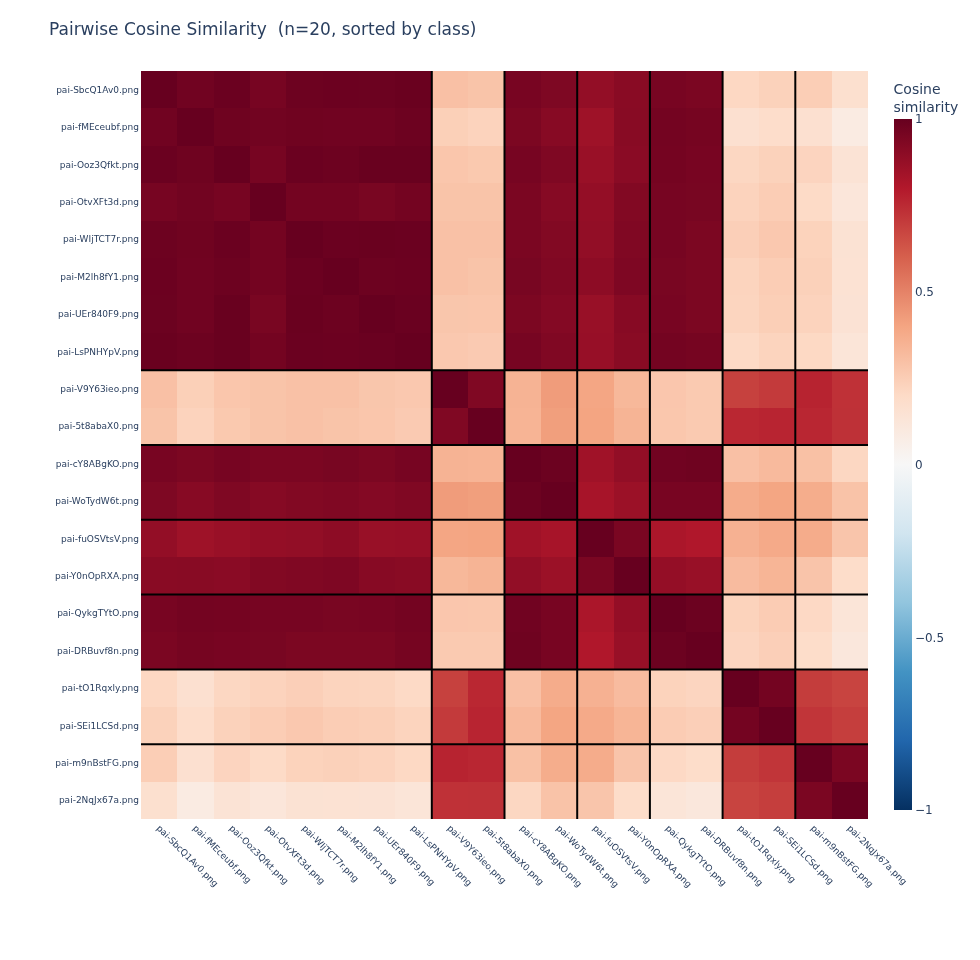

In [7]:
plot_cosine_similarity(embeddings, result, output_path=None)

  t-SNE 2D — fitting 20 samples (perplexity=3, iter=1000)...


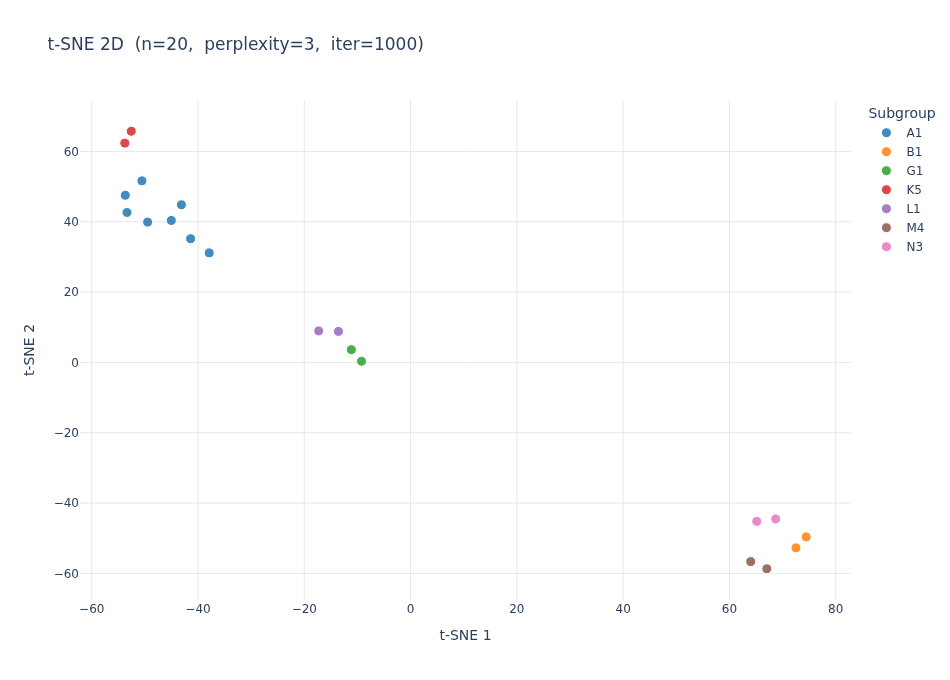

In [8]:
plot_tsne(embeddings, result, output_path=None, dimensions=2)

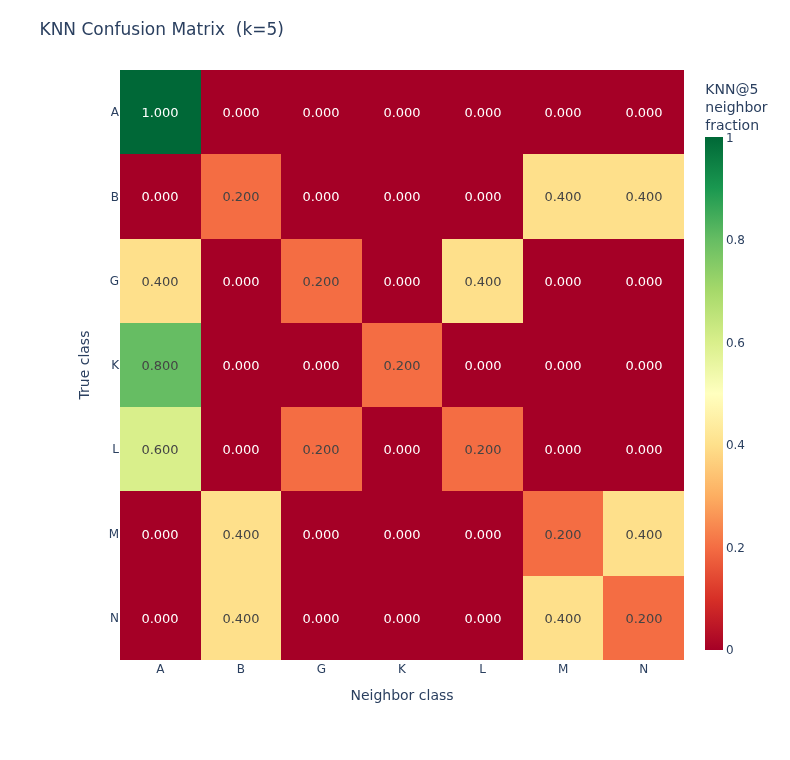

In [9]:
plot_knn_confusion(result, k=5, output_path=None)